# Submission Akhir DLTM — Multivariate Multi-Horizon Bitcoin Forecasting

## 1. Import Library dan Konfigurasi Awal

In [25]:
import os
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import tensorflow as tf
from tensorflow.keras import layers, Model

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


## 2. Load Dataset Bitcoin dari Link Dicoding

In [26]:
csv_url = "https://drive.google.com/uc?export=download&id=1hpsqSpfjdqIZWqwd259klQSeaNSe5Trr"
df = pd.read_csv(csv_url)

print("Shape awal:", df.shape)
display(df.head())
display(df.tail())
df.info()

Shape awal: (53150, 7)


,Date,Close,Volume USDT,RSI,MACD_Hist,ATR,KAMAO
0,2017-09-21 09:00:00.000,3860.00,74434.891166,49.192454,-48.279697,88.054720,2.495591
1,2017-09-21 10:00:00.000,3871.48,44687.318944,49.233202,-47.780476,87.996283,2.616710
2,2017-09-21 11:00:00.000,3864.95,80546.171672,49.210685,-47.308061,87.897128,2.532239
3,2017-09-21 12:00:00.000,3858.08,90331.531390,49.186948,-46.863233,87.720856,2.447245
4,2017-09-21 13:00:00.000,3856.67,103405.818040,49.182064,-46.425379,87.578086,2.424654


,Date,Close,Volume USDT,RSI,MACD_Hist,ATR,KAMAO
53145,2023-10-19 19:00:00,28750.75,2.984059e+07,53.630054,109.926882,129.065981,7.459700
53146,2023-10-19 20:00:00,28715.38,4.997623e+07,53.531282,111.721905,129.268969,7.118597
53147,2023-10-19 21:00:00,28604.09,3.205666e+07,53.221944,113.055031,129.287930,6.210037
53148,2023-10-19 22:00:00,28649.65,2.200420e+07,53.332673,114.513131,129.219782,6.515616
53149,2023-10-19 23:00:00,28713.71,1.758298e+07,53.487941,116.161806,129.096002,6.963753


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53150 entries, 0 to 53149
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         53150 non-null  object 
 1   Close        53150 non-null  float64
 2   Volume USDT  53150 non-null  float64
 3   RSI          53150 non-null  float64
 4   MACD_Hist    53150 non-null  float64
 5   ATR          53150 non-null  float64
 6   KAMAO        53150 non-null  float64
dtypes: float64(6), object(1)
memory usage: 2.8+ MB


## 3. Pemeriksaan Struktur Data dan Kolom Waktu

In [27]:
print(df.columns.tolist())

time_candidates = [
    col for col in df.columns
    if col.lower() in ['date', 'datetime', 'timestamp', 'time', 'open time', 'close time']
]

if len(time_candidates) > 0:
    time_col = time_candidates[0]

    try:
        df[time_col] = pd.to_datetime(df[time_col], format='mixed', errors='coerce')
    except TypeError:
        df[time_col] = pd.to_datetime(df[time_col], errors='coerce')

    n_invalid_date = df[time_col].isna().sum()
    print(f"Jumlah tanggal gagal diparse: {n_invalid_date}")

    df = df.dropna(subset=[time_col])
    df = df.sort_values(time_col).reset_index(drop=True)
    df = df.set_index(time_col)

else:
    print("Kolom waktu tidak ditemukan. Data akan menggunakan index default.")

df.head()

['Date', 'Close', 'Volume USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO']
Jumlah tanggal gagal diparse: 0


,Close,Volume USDT,RSI,MACD_Hist,ATR,KAMAO
Date,,,,,,
2017-09-21 09:00:00,3860.00,74434.891166,49.192454,-48.279697,88.054720,2.495591
2017-09-21 10:00:00,3871.48,44687.318944,49.233202,-47.780476,87.996283,2.616710
2017-09-21 11:00:00,3864.95,80546.171672,49.210685,-47.308061,87.897128,2.532239
2017-09-21 12:00:00,3858.08,90331.531390,49.186948,-46.863233,87.720856,2.447245
2017-09-21 13:00:00,3856.67,103405.818040,49.182064,-46.425379,87.578086,2.424654


## 4. Feature Engineering Rolling Statistic

In [28]:
# Pastikan kolom Close tersedia
assert "Close" in df.columns, "Kolom target 'Close' tidak ditemukan. Periksa nama kolom dataset."

# Pilih fitur numerik
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print("Kolom numerik:", numeric_cols)

# Rolling feature berbasis data historis
df["Close_roll_mean_24"] = df["Close"].rolling(window=24, min_periods=1).mean()
df["Close_roll_std_24"] = df["Close"].rolling(window=24, min_periods=1).std().fillna(0)

# Tambahan fitur kalender jika index berupa datetime
if isinstance(df.index, pd.DatetimeIndex):
    df["hour"] = df.index.hour
    df["dayofweek"] = df.index.dayofweek

display(df.head())

Kolom numerik: ['Close', 'Volume USDT', 'RSI', 'MACD_Hist', 'ATR', 'KAMAO']


,Close,Volume USDT,RSI,MACD_Hist,ATR,KAMAO,Close_roll_mean_24,Close_roll_std_24,hour,dayofweek
Date,,,,,,,,,,
2017-09-21 09:00:00,3860.00,74434.891166,49.192454,-48.279697,88.054720,2.495591,3860.000000,0.000000,9,3
2017-09-21 10:00:00,3871.48,44687.318944,49.233202,-47.780476,87.996283,2.616710,3865.740000,8.117586,10,3
2017-09-21 11:00:00,3864.95,80546.171672,49.210685,-47.308061,87.897128,2.532239,3865.476667,5.758093,11,3
2017-09-21 12:00:00,3858.08,90331.531390,49.186948,-46.863233,87.720856,2.447245,3863.627500,5.981758,12,3
2017-09-21 13:00:00,3856.67,103405.818040,49.182064,-46.425379,87.578086,2.424654,3862.236000,6.042965,13,3


## 5. Pemilihan Fitur Multivariate dan Heatmap Korelasi

Fitur input: ['Close', 'Close_roll_mean_24', 'Close_roll_std_24', 'hour', 'dayofweek']
Target: Close


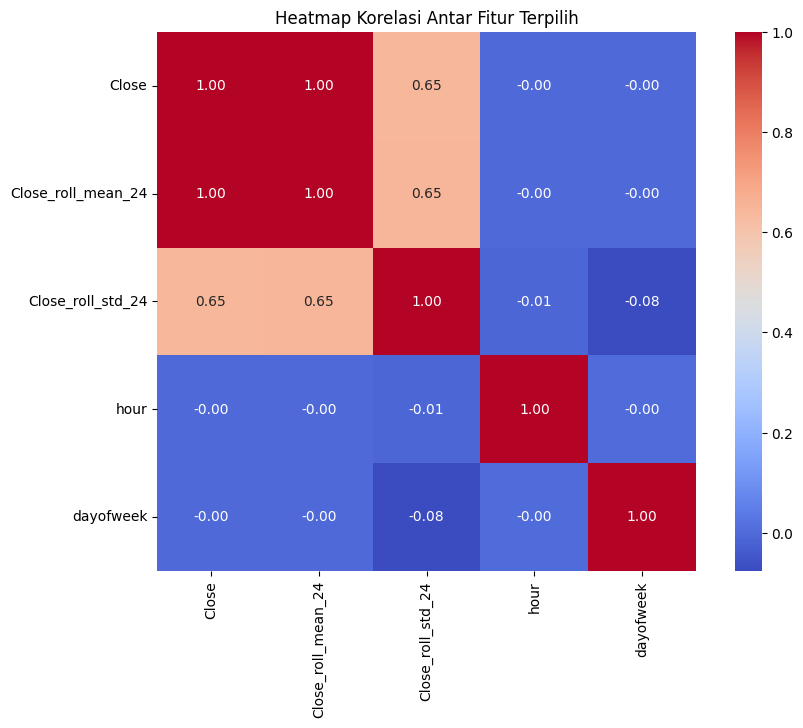

In [29]:
candidate_features = [
    "Open", "High", "Low", "Close", "Volume",
    "Close_roll_mean_24", "Close_roll_std_24", "hour", "dayofweek"
]
features = [c for c in candidate_features if c in df.columns]

# Pastikan minimal 3 fitur
assert len(features) >= 3, f"Fitur kurang dari 3. Fitur tersedia: {features}"

target_col = "Close"
target_idx = features.index(target_col)

print("Fitur input:", features)
print("Target:", target_col)

plt.figure(figsize=(10, 7))
sns.heatmap(df[features].corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Heatmap Korelasi Antar Fitur Terpilih")
plt.show()

## 6. Dekomposisi Target Close

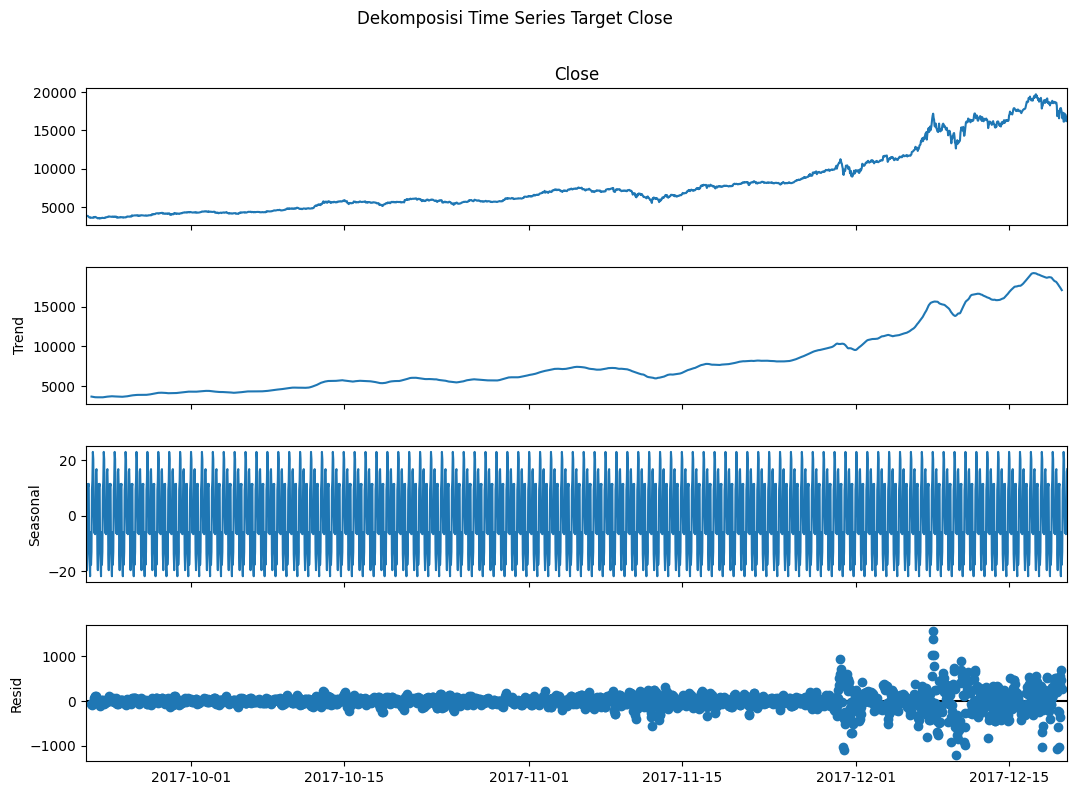

In [30]:
target_series = df[target_col].astype(float)

decomp_series = target_series.iloc[:min(len(target_series), 24*90)]

decomposition = seasonal_decompose(
    decomp_series,
    model="additive",
    period=24
)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.suptitle("Dekomposisi Time Series Target Close", y=1.02)
plt.show()

## 7. Analisis Lag Menggunakan ACF dan PACF

<Figure size 1200x400 with 0 Axes>

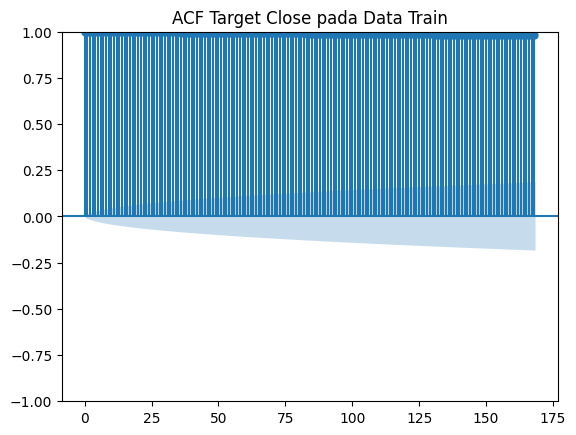

<Figure size 1200x400 with 0 Axes>

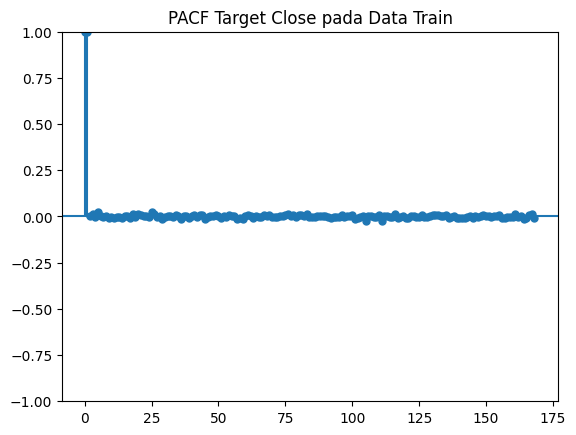

Input window size: 72
Forecast horizon: 24


In [31]:
train_size_for_lag = int(len(target_series) * 0.7)
lag_train_series = target_series.iloc[:train_size_for_lag]

max_lag = 168

plt.figure(figsize=(12, 4))
plot_acf(lag_train_series, lags=max_lag)
plt.title("ACF Target Close pada Data Train")
plt.show()

plt.figure(figsize=(12, 4))
plot_pacf(lag_train_series, lags=max_lag, method="ywm")
plt.title("PACF Target Close pada Data Train")
plt.show()

INPUT_WIDTH = 72
HORIZON = 24

print("Input window size:", INPUT_WIDTH)
print("Forecast horizon:", HORIZON)

## 8. Split Train, Validation, Test Sebelum Scaling

In [32]:
data = df[features].copy()

n = len(data)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = data.iloc[:train_end]
val_df = data.iloc[train_end:val_end]
test_df = data.iloc[val_end:]

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

scaler = StandardScaler()
train_scaled = scaler.fit_transform(train_df)
val_scaled = scaler.transform(val_df)
test_scaled = scaler.transform(test_df)

print("Scaling selesai tanpa data leakage.")

Train: (37205, 5)
Validation: (7972, 5)
Test: (7973, 5)
Scaling selesai tanpa data leakage.


## 9. Membuat Window Multi-Step dan Dataset `tf.data`

In [33]:
def make_windows(array, target_index, input_width=72, horizon=24):
    X, decoder_in, y = [], [], []
    total = len(array)

    for start in range(total - input_width - horizon + 1):
        end = start + input_width
        out_end = end + horizon

        x_window = array[start:end]
        y_window = array[end:out_end, target_index]

        dec = np.zeros((horizon, 1), dtype=np.float32)
        dec[0, 0] = array[end - 1, target_index]
        dec[1:, 0] = y_window[:-1]

        X.append(x_window)
        decoder_in.append(dec)
        y.append(y_window.reshape(-1, 1))

    return (
        np.array(X, dtype=np.float32),
        np.array(decoder_in, dtype=np.float32),
        np.array(y, dtype=np.float32)
    )

X_train, dec_train, y_train = make_windows(train_scaled, target_idx, INPUT_WIDTH, HORIZON)
X_val, dec_val, y_val = make_windows(val_scaled, target_idx, INPUT_WIDTH, HORIZON)
X_test, dec_test, y_test = make_windows(test_scaled, target_idx, INPUT_WIDTH, HORIZON)

print("X_train:", X_train.shape, "dec_train:", dec_train.shape, "y_train:", y_train.shape)
print("X_val:", X_val.shape, "dec_val:", dec_val.shape, "y_val:", y_val.shape)
print("X_test:", X_test.shape, "dec_test:", dec_test.shape, "y_test:", y_test.shape)

BATCH_SIZE = 64
AUTOTUNE = tf.data.AUTOTUNE

train_ds_baseline = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(2048, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds_baseline = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds_baseline = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

train_ds_seq2seq = (
    tf.data.Dataset.from_tensor_slices(((X_train, dec_train), y_train))
    .shuffle(2048, seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

val_ds_seq2seq = (
    tf.data.Dataset.from_tensor_slices(((X_val, dec_val), y_val))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_ds_seq2seq = (
    tf.data.Dataset.from_tensor_slices(((X_test, dec_test), y_test))
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

X_train: (37110, 72, 5) dec_train: (37110, 24, 1) y_train: (37110, 24, 1)
X_val: (7877, 72, 5) dec_val: (7877, 24, 1) y_val: (7877, 24, 1)
X_test: (7878, 72, 5) dec_test: (7878, 24, 1) y_test: (7878, 24, 1)


## 10. Custom Layer: Dense, Dropout, dan Multi-Head Attention dari Nol

In [34]:
@tf.keras.utils.register_keras_serializable()
class CustomDense(layers.Layer):
    def __init__(self, units, activation=None, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.activation = tf.keras.activations.get(activation)

    def build(self, input_shape):
        last_dim = int(input_shape[-1])
        self.kernel = self.add_weight(
            name="kernel",
            shape=(last_dim, self.units),
            initializer="glorot_uniform",
            trainable=True
        )
        self.bias = self.add_weight(
            name="bias",
            shape=(self.units,),
            initializer="zeros",
            trainable=True
        )

    def call(self, inputs):
        outputs = tf.matmul(inputs, self.kernel) + self.bias
        if self.activation is not None:
            outputs = self.activation(outputs)
        return outputs

    def get_config(self):
        config = super().get_config()
        config.update({
            "units": self.units,
            "activation": tf.keras.activations.serialize(self.activation)
        })
        return config


@tf.keras.utils.register_keras_serializable()
class CustomDropout(layers.Layer):
    def __init__(self, rate, **kwargs):
        super().__init__(**kwargs)
        self.rate = rate

    def call(self, inputs, training=False):
        if training:
            return tf.nn.dropout(inputs, rate=self.rate)
        return inputs

    def get_config(self):
        config = super().get_config()
        config.update({"rate": self.rate})
        return config


@tf.keras.utils.register_keras_serializable()
class CustomMultiHeadAttention(layers.Layer):
    def __init__(self, d_model, num_heads, **kwargs):
        super().__init__(**kwargs)
        assert d_model % num_heads == 0, "d_model harus habis dibagi num_heads."
        self.d_model = d_model
        self.num_heads = num_heads
        self.depth = d_model // num_heads

        self.wq = CustomDense(d_model)
        self.wk = CustomDense(d_model)
        self.wv = CustomDense(d_model)
        self.wo = CustomDense(d_model)

    def split_heads(self, x):
        batch_size = tf.shape(x)[0]
        x = tf.reshape(x, (batch_size, -1, self.num_heads, self.depth))
        return tf.transpose(x, perm=[0, 2, 1, 3])

    def scaled_dot_product_attention(self, q, k, v):
        matmul_qk = tf.matmul(q, k, transpose_b=True)
        dk = tf.cast(tf.shape(k)[-1], tf.float32)
        scores = matmul_qk / tf.math.sqrt(dk)
        weights = tf.nn.softmax(scores, axis=-1)
        output = tf.matmul(weights, v)
        return output, weights

    def call(self, query, key=None, value=None):
        if key is None:
            key = query
        if value is None:
            value = key

        q = self.split_heads(self.wq(query))
        k = self.split_heads(self.wk(key))
        v = self.split_heads(self.wv(value))

        attention_output, attention_weights = self.scaled_dot_product_attention(q, k, v)

        attention_output = tf.transpose(attention_output, perm=[0, 2, 1, 3])
        batch_size = tf.shape(attention_output)[0]
        concat_attention = tf.reshape(attention_output, (batch_size, -1, self.d_model))

        return self.wo(concat_attention)

    def get_config(self):
        config = super().get_config()
        config.update({
            "d_model": self.d_model,
            "num_heads": self.num_heads
        })
        return config

## 11. Model Baseline LSTM Multi-Step dengan Custom Layer dan Attention

In [35]:
def build_baseline_lstm(input_width, n_features, horizon):
    encoder_inputs = layers.Input(
        shape=(input_width, n_features),
        name="baseline_encoder_input"
    )

    x = layers.LSTM(
        128,
        return_sequences=True,
        name="baseline_lstm_encoder"
    )(encoder_inputs)

    attn = CustomMultiHeadAttention(
        d_model=128,
        num_heads=4,
        name="baseline_custom_mha"
    )(x)

    x = layers.Add(name="baseline_attention_residual")([x, attn])
    x = layers.LayerNormalization(name="baseline_layer_norm")(x)

    x = layers.GlobalAveragePooling1D(name="baseline_context_pooling")(x)

    x = CustomDropout(0.2, name="baseline_custom_dropout")(x)

    x = CustomDense(horizon, name="baseline_dense_horizon_output")(x)

    outputs = layers.Reshape(
        (horizon, 1),
        name="baseline_reshape_horizon"
    )(x)

    model = Model(encoder_inputs, outputs, name="model_baseline_LSTM")
    return model

## 12. Training Baseline LSTM

In [36]:
baseline_model = build_baseline_lstm(
    INPUT_WIDTH,
    len(features),
    HORIZON
)
baseline_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mae",
    metrics=["mae"]
)

baseline_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
]

history_baseline = baseline_model.fit(
    train_ds_baseline,
    validation_data=val_ds_baseline,
    epochs=20,
    callbacks=baseline_callbacks
)

Epoch 1/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 151s 254ms/step - loss: 0.1197 - mae: 0.1197 - val_loss: 0.0774 - val_mae: 0.0774
Epoch 2/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 147s 254ms/step - loss: 0.0635 - mae: 0.0635 - val_loss: 0.0599 - val_mae: 0.0599
Epoch 3/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 147s 254ms/step - loss: 0.0599 - mae: 0.0599 - val_loss: 0.0585 - val_mae: 0.0585
Epoch 4/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 203s 256ms/step - loss: 0.0526 - mae: 0.0526 - val_loss: 0.0561 - val_mae: 0.0561
Epoch 5/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 148s 256ms/step - loss: 0.0504 - mae: 0.0504 - val_loss: 0.0506 - val_mae: 0.0506
Epoch 6/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 148s 255ms/step - loss: 0.0483 - mae: 0.0483 - val_loss: 0.0607 - val_mae: 0.0607
Epoch 7/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 148s 255ms/step - loss: 0.0465 - mae: 0.0465 - val_loss: 0.0561 - val_mae: 0.0561
Epoch 8/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 148s 256ms/step - loss: 0.0458 - mae: 0.0458 - val_loss: 0.0575 - val_mae: 0.0575
Epoch 9/20
580/580 ━━━━━

## 13. Seq2Seq LSTM Teacher Forcing dengan Functional API

In [37]:
def build_seq2seq_lstm_functional(input_width, n_features, horizon):
    encoder_inputs = layers.Input(shape=(input_width, n_features), name="encoder_input")
    decoder_inputs = layers.Input(shape=(horizon, 1), name="decoder_teacher_input")

    encoder_outputs, state_h, state_c = layers.LSTM(
        128,
        return_sequences=True,
        return_state=True,
        name="seq2seq_encoder_lstm"
    )(encoder_inputs)

    decoder_outputs = layers.LSTM(
        128,
        return_sequences=True,
        name="seq2seq_decoder_lstm"
    )(decoder_inputs, initial_state=[state_h, state_c])

    cross_attention = CustomMultiHeadAttention(
        d_model=128,
        num_heads=4,
        name="seq2seq_custom_cross_attention"
    )(decoder_outputs, encoder_outputs, encoder_outputs)

    x = layers.Add(name="seq2seq_attention_residual")([decoder_outputs, cross_attention])
    x = layers.LayerNormalization(name="seq2seq_layer_norm")(x)
    x = CustomDropout(0.2, name="seq2seq_custom_dropout")(x)
    outputs = CustomDense(1, name="seq2seq_custom_dense_output")(x)

    model = Model([encoder_inputs, decoder_inputs], outputs, name="model_seq2seq_LSTM")
    return model

seq2seq_model = build_seq2seq_lstm_functional(INPUT_WIDTH, len(features), HORIZON)
seq2seq_model.summary()

Model: "model_seq2seq_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 72, 5)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_teacher_in… │ (None, 24, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ seq2seq_encoder_ls… │ [(None, 72, 128), │     68,608 │ encoder_input[0]… │
│ (LSTM)              │ (None, 128),      │            │                   │
│                     │ (None, 128)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ seq2seq_decoder_ls… │ (None, 24, 128)   │     66,560 │ decoder_teacher_… │
│ (LSTM)              │                   │            │ seq2seq_encoder_… │
│                     │                   │            │ seq2seq_encoder_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ seq2seq_custom_cro… │ (None, None, 128) │     66,048 │ seq2seq_decoder_… │
│ (CustomMultiHeadAt… │                   │            │ seq2seq_encoder_… │
│                     │                   │            │ seq2seq_encoder_… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ seq2seq_attention_… │ (None, None, 128) │          0 │ seq2seq_decoder_… │
│ (Add)               │                   │            │ seq2seq_custom_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ seq2seq_layer_norm  │ (None, None, 128) │        256 │ seq2seq_attentio… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ seq2seq_custom_dro… │ (None, None, 128) │          0 │ seq2seq_layer_no… │
│ (CustomDropout)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ seq2seq_custom_den… │ (None, None, 1)   │        129 │ seq2seq_custom_d… │
│ (CustomDense)       │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 201,601 (787.50 KB)

 Trainable params: 201,601 (787.50 KB)

 Non-trainable params: 0 (0.00 B)

## 14. Training Awal Seq2Seq Functional

In [38]:
seq2seq_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mae",
    metrics=["mae"]
)

seq2seq_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    )
]

history_seq2seq_fit = seq2seq_model.fit(
    train_ds_seq2seq,
    validation_data=val_ds_seq2seq,
    epochs=20,
    callbacks=seq2seq_callbacks
)

Epoch 1/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 149s 248ms/step - loss: 0.1021 - mae: 0.1021 - val_loss: 0.0518 - val_mae: 0.0518
Epoch 2/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 143s 246ms/step - loss: 0.0521 - mae: 0.0521 - val_loss: 0.1140 - val_mae: 0.1140
Epoch 3/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 142s 244ms/step - loss: 0.0427 - mae: 0.0427 - val_loss: 0.0511 - val_mae: 0.0511
Epoch 4/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 143s 246ms/step - loss: 0.0368 - mae: 0.0368 - val_loss: 0.0178 - val_mae: 0.0178
Epoch 5/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 143s 246ms/step - loss: 0.0346 - mae: 0.0346 - val_loss: 0.0175 - val_mae: 0.0175
Epoch 6/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 141s 243ms/step - loss: 0.0352 - mae: 0.0352 - val_loss: 0.0135 - val_mae: 0.0135
Epoch 7/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 143s 246ms/step - loss: 0.0324 - mae: 0.0324 - val_loss: 0.0125 - val_mae: 0.0125
Epoch 8/20
580/580 ━━━━━━━━━━━━━━━━━━━━ 142s 246ms/step - loss: 0.0320 - mae: 0.0320 - val_loss: 0.0133 - val_mae: 0.0133
Epoch 9/20
580/580 ━━━━━

## 15. Seq2Seq LSTM dengan Model Subclassing

In [39]:
@tf.keras.utils.register_keras_serializable()
class Seq2SeqLSTMSubclass(tf.keras.Model):
    def __init__(self, units=128, d_model=128, num_heads=4, dropout_rate=0.2, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.d_model = d_model
        self.num_heads = num_heads
        self.dropout_rate = dropout_rate

        self.encoder_lstm = layers.LSTM(
            units,
            return_sequences=True,
            return_state=True,
            name="subclass_encoder_lstm"
        )
        self.decoder_lstm = layers.LSTM(
            units,
            return_sequences=True,
            name="subclass_decoder_lstm"
        )
        self.attention = CustomMultiHeadAttention(
            d_model=d_model,
            num_heads=num_heads,
            name="subclass_custom_mha"
        )
        self.add = layers.Add(name="subclass_residual_add")
        self.norm = layers.LayerNormalization(name="subclass_layer_norm")
        self.dropout = CustomDropout(dropout_rate, name="subclass_custom_dropout")
        self.output_dense = CustomDense(1, name="subclass_custom_dense_output")

    def call(self, inputs, training=False):
        encoder_inputs, decoder_inputs = inputs

        encoder_outputs, state_h, state_c = self.encoder_lstm(encoder_inputs, training=training)
        decoder_outputs = self.decoder_lstm(
            decoder_inputs,
            initial_state=[state_h, state_c],
            training=training
        )

        attn = self.attention(decoder_outputs, encoder_outputs, encoder_outputs)
        x = self.add([decoder_outputs, attn])
        x = self.norm(x)
        x = self.dropout(x, training=training)
        return self.output_dense(x)

    def get_config(self):
        config = super().get_config()
        config.update({
            "units": self.units,
            "d_model": self.d_model,
            "num_heads": self.num_heads,
            "dropout_rate": self.dropout_rate
        })
        return config

subclass_seq2seq_model = Seq2SeqLSTMSubclass(name="subclass_seq2seq_LSTM")
_ = subclass_seq2seq_model((X_train[:2], dec_train[:2]))
subclass_seq2seq_model.summary()

subclass_seq2seq_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mae",
    metrics=["mae"]
)

history_subclass = subclass_seq2seq_model.fit(
    train_ds_seq2seq,
    validation_data=val_ds_seq2seq,
    epochs=5
)

Model: "subclass_seq2seq_LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ subclass_encoder_lstm (LSTM)    │ ((2, 72, 128), (2,     │        68,608 │
│                                 │ 128), (2, 128))        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subclass_decoder_lstm (LSTM)    │ (2, 24, 128)           │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subclass_custom_mha             │ ?                      │        66,048 │
│ (CustomMultiHeadAttention)      │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subclass_residual_add (Add)     │ (2, 24, 128)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subclass_layer_norm             │ (2, 24, 128)           │           256 │
│ (LayerNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subclass_custom_dropout         │ ?                      │             0 │
│ (CustomDropout)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subclass_custom_dense_output    │ ?                      │           129 │
│ (CustomDense)                   │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 201,601 (787.50 KB)

 Trainable params: 201,601 (787.50 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
580/580 ━━━━━━━━━━━━━━━━━━━━ 147s 243ms/step - loss: 0.1445 - mae: 0.1445 - val_loss: 0.0461 - val_mae: 0.0461
Epoch 2/5
580/580 ━━━━━━━━━━━━━━━━━━━━ 143s 244ms/step - loss: 0.0535 - mae: 0.0535 - val_loss: 0.0408 - val_mae: 0.0408
Epoch 3/5
580/580 ━━━━━━━━━━━━━━━━━━━━ 142s 245ms/step - loss: 0.0441 - mae: 0.0441 - val_loss: 0.0186 - val_mae: 0.0186
Epoch 4/5
580/580 ━━━━━━━━━━━━━━━━━━━━ 141s 244ms/step - loss: 0.0420 - mae: 0.0420 - val_loss: 0.0175 - val_mae: 0.0175
Epoch 5/5
580/580 ━━━━━━━━━━━━━━━━━━━━ 142s 244ms/step - loss: 0.0362 - mae: 0.0362 - val_loss: 0.0266 - val_mae: 0.0266


## 16. Custom Loss, Custom Early Stopping, dan Custom LR Reducer

In [40]:
def custom_mae_loss(y_true, y_pred):
    return tf.reduce_mean(tf.abs(y_true - y_pred))

def weighted_horizon_mae(y_true, y_pred):
    weights = tf.linspace(1.0, 1.8, HORIZON)
    weights = tf.reshape(weights, (1, HORIZON, 1))
    error = tf.abs(y_true - y_pred)
    weighted_error = error * weights
    return tf.reduce_mean(weighted_error)

class CustomEarlyStopping:
    def __init__(self, patience=5, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best = np.inf
        self.wait = 0
        self.best_weights = None
        self.stop_training = False

    def on_epoch_end(self, model, val_loss):
        if val_loss < self.best - self.min_delta:
            self.best = val_loss
            self.wait = 0
            self.best_weights = model.get_weights()
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.stop_training = True
                if self.best_weights is not None:
                    model.set_weights(self.best_weights)

class CustomReduceLROnPlateau:
    def __init__(self, optimizer, patience=3, factor=0.5, min_lr=1e-6, min_delta=1e-5):
        self.optimizer = optimizer
        self.patience = patience
        self.factor = factor
        self.min_lr = min_lr
        self.min_delta = min_delta

        self.best = np.inf
        self.wait = 0

    def _get_lr(self):
        lr = self.optimizer.learning_rate
        if hasattr(lr, "numpy"):
            return float(lr.numpy())
        return float(tf.keras.backend.get_value(lr))

    def _set_lr(self, new_lr):
        lr = self.optimizer.learning_rate

        if hasattr(lr, "assign"):
            lr.assign(new_lr)
        else:
            self.optimizer.learning_rate = new_lr

    def on_epoch_end(self, val_loss):
        if val_loss < self.best - self.min_delta:
            self.best = val_loss
            self.wait = 0
        else:
            self.wait += 1

            if self.wait >= self.patience:
                old_lr = self._get_lr()
                new_lr = max(old_lr * self.factor, self.min_lr)

                self._set_lr(new_lr)

                print(f"Learning rate reduced: {old_lr:.8f} -> {new_lr:.8f}")
                self.wait = 0

## 17. Custom Training Loop dengan `tf.GradientTape`

Epoch 01/30 - loss: 0.201129 - val_loss: 0.101785 - lr: 0.00100000
Epoch 02/30 - loss: 0.061349 - val_loss: 0.096673 - lr: 0.00100000
Epoch 03/30 - loss: 0.062502 - val_loss: 0.078776 - lr: 0.00100000
Epoch 04/30 - loss: 0.050338 - val_loss: 0.078017 - lr: 0.00100000
Epoch 05/30 - loss: 0.052596 - val_loss: 0.091589 - lr: 0.00100000
Epoch 06/30 - loss: 0.048607 - val_loss: 0.042536 - lr: 0.00100000
Epoch 07/30 - loss: 0.048850 - val_loss: 0.070253 - lr: 0.00100000
Epoch 08/30 - loss: 0.046579 - val_loss: 0.048426 - lr: 0.00100000
Epoch 09/30 - loss: 0.045165 - val_loss: 0.069610 - lr: 0.00100000
Learning rate reduced: 0.00100000 -> 0.00050000
Epoch 10/30 - loss: 0.041840 - val_loss: 0.051958 - lr: 0.00050000
Epoch 11/30 - loss: 0.041450 - val_loss: 0.047625 - lr: 0.00050000
Epoch 12/30 - loss: 0.041659 - val_loss: 0.044505 - lr: 0.00050000
Learning rate reduced: 0.00050000 -> 0.00025000
Custom early stopping aktif. Training dihentikan.
Best weights dari validation loss terbaik berhasil

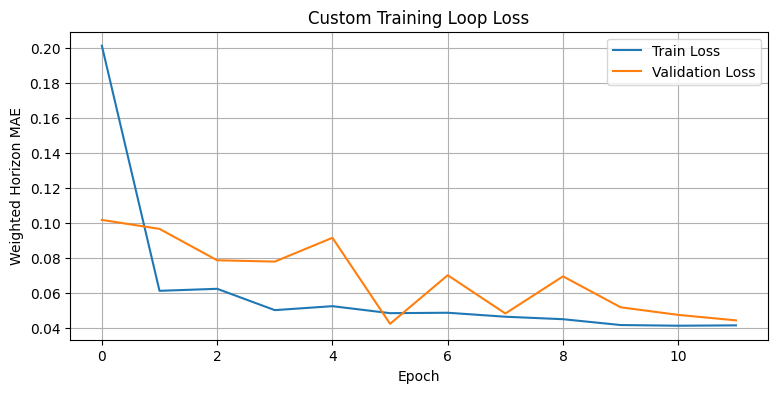

In [41]:
best_seq2seq_lstm_model = build_seq2seq_lstm_functional(
    INPUT_WIDTH,
    len(features),
    HORIZON
)

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)

early_stopping = CustomEarlyStopping(
    patience=6,
    min_delta=1e-5
)

lr_reducer = CustomReduceLROnPlateau(
    optimizer=optimizer,
    patience=3,
    factor=0.5,
    min_lr=1e-6,
    min_delta=1e-5
)

train_loss_history = []
val_loss_history = []

EPOCHS_CUSTOM = 30

for epoch in range(1, EPOCHS_CUSTOM + 1):
    train_losses = []

    for (batch_x, batch_dec), batch_y in train_ds_seq2seq:
        batch_x = tf.cast(batch_x, tf.float32)
        batch_dec = tf.cast(batch_dec, tf.float32)
        batch_y = tf.cast(batch_y, tf.float32)

        with tf.GradientTape() as tape:
            preds = best_seq2seq_lstm_model(
                [batch_x, batch_dec],
                training=True
            )
            loss = weighted_horizon_mae(batch_y, preds)

        gradients = tape.gradient(
            loss,
            best_seq2seq_lstm_model.trainable_variables
        )

        grads_and_vars = [
            (grad, var)
            for grad, var in zip(gradients, best_seq2seq_lstm_model.trainable_variables)
            if grad is not None
        ]

        optimizer.apply_gradients(grads_and_vars)
        train_losses.append(float(loss.numpy()))

    val_losses = []

    for (batch_x, batch_dec), batch_y in val_ds_seq2seq:
        batch_x = tf.cast(batch_x, tf.float32)
        batch_dec = tf.cast(batch_dec, tf.float32)
        batch_y = tf.cast(batch_y, tf.float32)

        val_preds = best_seq2seq_lstm_model(
            [batch_x, batch_dec],
            training=False
        )

        val_loss_batch = weighted_horizon_mae(batch_y, val_preds)
        val_losses.append(float(val_loss_batch.numpy()))

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))

    train_loss_history.append(train_loss)
    val_loss_history.append(val_loss)

    current_lr = lr_reducer._get_lr()

    print(
        f"Epoch {epoch:02d}/{EPOCHS_CUSTOM} - "
        f"loss: {train_loss:.6f} - "
        f"val_loss: {val_loss:.6f} - "
        f"lr: {current_lr:.8f}"
    )

    lr_reducer.on_epoch_end(val_loss)
    early_stopping.on_epoch_end(best_seq2seq_lstm_model, val_loss)

    if early_stopping.stop_training:
        print("Custom early stopping aktif. Training dihentikan.")
        break

# Restore bobot terbaik jika tersedia
if early_stopping.best_weights is not None:
    best_seq2seq_lstm_model.set_weights(early_stopping.best_weights)
    print("Best weights dari validation loss terbaik berhasil dipulihkan.")

plt.figure(figsize=(9, 4))
plt.plot(train_loss_history, label="Train Loss")
plt.plot(val_loss_history, label="Validation Loss")
plt.title("Custom Training Loop Loss")
plt.xlabel("Epoch")
plt.ylabel("Weighted Horizon MAE")
plt.legend()
plt.grid(True)
plt.show()

## 18. Fungsi Inverse Scaling untuk Target Close

In [42]:
def inverse_close_scaled(close_scaled_values, scaler, target_index):
    close_scaled_values = np.array(close_scaled_values)
    dummy = np.zeros((close_scaled_values.size, len(features)))
    dummy[:, target_index] = close_scaled_values.reshape(-1)
    inversed = scaler.inverse_transform(dummy)[:, target_index]
    return inversed.reshape(close_scaled_values.shape)

def evaluate_scaled_mae(y_true, y_pred, name):
    mae = mean_absolute_error(y_true.reshape(-1), y_pred.reshape(-1))
    rmse = np.sqrt(mean_squared_error(y_true.reshape(-1), y_pred.reshape(-1)))
    print(f"{name} - MAE scaled: {mae:.6f}")
    print(f"{name} - RMSE scaled: {rmse:.6f}")
    return mae, rmse

## 19. Inference Baseline LSTM pada Data Test

In [43]:
baseline_pred_scaled = baseline_model.predict(X_test, batch_size=BATCH_SIZE)
baseline_mae_scaled, baseline_rmse_scaled = evaluate_scaled_mae(
    y_test,
    baseline_pred_scaled,
    "Baseline LSTM"
)

baseline_pred_inv = inverse_close_scaled(baseline_pred_scaled, scaler, target_idx)
y_test_inv = inverse_close_scaled(y_test, scaler, target_idx)

124/124 ━━━━━━━━━━━━━━━━━━━━ 12s 92ms/step
Baseline LSTM - MAE scaled: 0.022679
Baseline LSTM - RMSE scaled: 0.031963


## 20. Inference Seq2Seq Autoregressive pada Data Test

In [44]:
def batch_autoregressive_forecast(model, X, horizon=24, batch_size=256):
    all_predictions = []

    for start in range(0, len(X), batch_size):
        end = min(start + batch_size, len(X))

        encoder_input = tf.convert_to_tensor(X[start:end], dtype=tf.float32)
        n_batch = end - start

        last_target = encoder_input[:, -1, target_idx].numpy()

        decoder_sequence = np.zeros((n_batch, horizon, 1), dtype=np.float32)
        decoder_sequence[:, 0, 0] = last_target

        batch_predictions = np.zeros((n_batch, horizon, 1), dtype=np.float32)

        for step in range(horizon):
            decoder_tensor = tf.convert_to_tensor(decoder_sequence, dtype=tf.float32)

            pred_full = model(
                [encoder_input, decoder_tensor],
                training=False
            )

            step_pred = pred_full[:, step, 0].numpy()
            batch_predictions[:, step, 0] = step_pred

            if step + 1 < horizon:
                decoder_sequence[:, step + 1, 0] = step_pred

        all_predictions.append(batch_predictions)

    return np.concatenate(all_predictions, axis=0)


seq2seq_pred_scaled = batch_autoregressive_forecast(
    best_seq2seq_lstm_model,
    X_test,
    horizon=HORIZON,
    batch_size=256
)

print("Shape prediksi Seq2Seq:", seq2seq_pred_scaled.shape)
print("Shape y_test:", y_test.shape)

seq2seq_mae_scaled, seq2seq_rmse_scaled = evaluate_scaled_mae(
    y_test,
    seq2seq_pred_scaled,
    "Best Seq2Seq LSTM Autoregressive"
)

seq2seq_pred_inv = inverse_close_scaled(
    seq2seq_pred_scaled,
    scaler,
    target_idx
)

y_test_seq_inv = inverse_close_scaled(
    y_test,
    scaler,
    target_idx
)
print("Shape prediksi Seq2Seq:", seq2seq_pred_scaled.shape)
print("Shape y_test:", y_test.shape)

Shape prediksi Seq2Seq: (7878, 24, 1)
Shape y_test: (7878, 24, 1)
Best Seq2Seq LSTM Autoregressive - MAE scaled: 0.229510
Best Seq2Seq LSTM Autoregressive - RMSE scaled: 1.004207
Shape prediksi Seq2Seq: (7878, 24, 1)
Shape y_test: (7878, 24, 1)


## 21. Visualisasi Prediksi Line Chart dan Tabel Aktual vs Prediksi

,Horizon,Actual_Close,Predicted_Close,Selisih
0,1,16586.730015,16476.373619,110.356396
1,2,16583.310005,16345.898225,237.411780
2,3,16577.409995,16242.287179,335.122816
3,4,16567.360014,16164.681121,402.678893
4,5,16551.950001,16105.439712,446.510289
5,6,16612.479999,16053.599009,558.880990
6,7,16598.950004,16001.466065,597.483939
7,8,16528.789994,15945.617333,583.172661
8,9,16526.840002,15885.546020,641.293983
9,10,16525.779984,15822.194193,703.585791


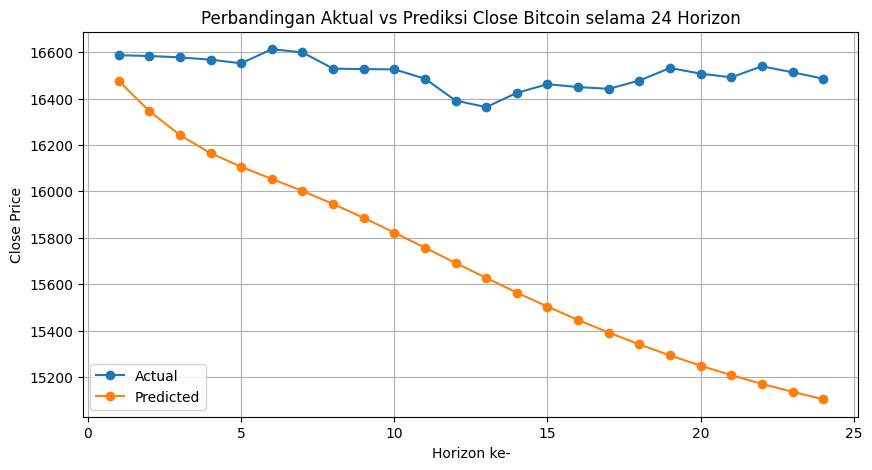

In [45]:
sample_id = 0

comparison_df = pd.DataFrame({
    "Horizon": np.arange(1, HORIZON + 1),
    "Actual_Close": y_test_seq_inv[sample_id, :, 0],
    "Predicted_Close": seq2seq_pred_inv[sample_id, :, 0]
})
comparison_df["Selisih"] = np.abs(
    comparison_df["Actual_Close"] - comparison_df["Predicted_Close"]
)

display(comparison_df)

plt.figure(figsize=(10, 5))
plt.plot(comparison_df["Horizon"], comparison_df["Actual_Close"], marker="o", label="Actual")
plt.plot(comparison_df["Horizon"], comparison_df["Predicted_Close"], marker="o", label="Predicted")
plt.title("Perbandingan Aktual vs Prediksi Close Bitcoin selama 24 Horizon")
plt.xlabel("Horizon ke-")
plt.ylabel("Close Price")
plt.legend()
plt.grid(True)
plt.show()

## 22. Ringkasan Evaluasi Model

In [46]:
summary_eval = pd.DataFrame({
    "Model": [
        "Baseline LSTM",
        "Best Seq2Seq LSTM Autoregressive"
    ],
    "MAE_scaled": [
        baseline_mae_scaled,
        seq2seq_mae_scaled
    ],
    "RMSE_scaled": [
        baseline_rmse_scaled,
        seq2seq_rmse_scaled
    ]
})

display(summary_eval)

if seq2seq_mae_scaled < 0.015:
    print("Kriteria Advanced performa terpenuhi: MAE test scaled < 0.015")
else:
    print("MAE test scaled belum < 0.015. Coba tuning INPUT_WIDTH, units LSTM, learning rate, batch size, atau epoch.")

,Model,MAE_scaled,RMSE_scaled
0,Baseline LSTM,0.022679,0.031963
1,Best Seq2Seq LSTM Autoregressive,0.229510,1.004207


MAE test scaled belum < 0.015. Coba tuning INPUT_WIDTH, units LSTM, learning rate, batch size, atau epoch.


## 23. Menyimpan Model dalam Format `.keras`

In [47]:
baseline_model.save("model_baseline_LSTM.keras")
seq2seq_model.save("model_seq2seq_LSTM.keras")
best_seq2seq_lstm_model.save("best_model_seq2seq_LSTM.keras")

print("Model berhasil disimpan:")
print("- model_baseline_LSTM.keras")
print("- model_seq2seq_LSTM.keras")
print("- best_model_seq2seq_LSTM.keras")

Model berhasil disimpan:
- model_baseline_LSTM.keras
- model_seq2seq_LSTM.keras
- best_model_seq2seq_LSTM.keras
